In [685]:
import pandas as pd
import numpy as np

In [686]:
df = pd.read_csv("../data/bronze/Property.csv", sep = ";")

In [687]:
df.head(1)

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan


Limpieza general

In [688]:
df = df.drop(columns=["property_id","agency","agent","page_url"])

In [689]:
print(len(df))
df = df.drop_duplicates()
print(len(df))

191393
168635


Limpieza Variables:

Primera vuelta limpieza: 

Variable baths

In [690]:
df["baths"].value_counts()

baths
0      40688
3      33077
2      25330
4      20615
6      17354
5      16122
1       5840
7       5735
8       2133
10       962
9        754
12        10
11         7
13         3
14         3
403        1
15         1
Name: count, dtype: int64

In [691]:
df = df[df["baths"] < 7]

In [692]:
len(df)

159026

Variable bedrooms: 

In [693]:
df["bedrooms"].value_counts()

bedrooms
3     45014
2     30749
4     23957
5     22949
0     19991
6      8787
1      5065
7       986
8       695
9       348
10      337
11       87
12       25
15        8
14        7
16        4
25        4
13        3
28        3
20        2
27        2
18        1
68        1
21        1
Name: count, dtype: int64

In [694]:
df = df[df["bedrooms"]<7]
len(df)

156512

Variables bedroom - bathroom conjuntas: 

In [695]:
df.groupby("bedrooms")["baths"].value_counts().unstack(fill_value=0)

baths,0,1,2,3,4,5,6
bedrooms,,,,,,,
0,19632,84,96,71,39,29,40
1,695,3676,670,17,4,2,1
2,4396,1762,20850,3541,158,23,19
3,6527,249,2609,27035,7794,754,46
4,3419,47,827,1396,11146,6087,1035
5,3085,9,168,586,854,8444,9803
6,1962,7,82,309,367,492,5568


In [696]:
df = df[~((df["bedrooms"] == 0) & (df["baths"] > 0))].reset_index(drop=True)

In [697]:
df = df[~((df["baths"] == 0) & (df["bedrooms"] > 1))].reset_index(drop=True)

In [698]:
n_antes = len(df)
df = df.query("not (bedrooms == 0 and baths == 0)").reset_index(drop=True)
print(f"Filas eliminadas: {n_antes - len(df)}")

Filas eliminadas: 19632


Variable city:

In [699]:
df["city"].value_counts()

city
Lahore        39370
Karachi       38194
Islamabad     24291
Rawalpindi    12912
Faisalabad     2365
Name: count, dtype: int64

Variable date_added: 

In [700]:
df["date_added"] = pd.to_datetime(df["date_added"])
df["date_added"].dtype

dtype('<M8[ns]')

Variable location: 

In [701]:
df["location"].value_counts()

location
DHA Defence                 17896
Bahria Town Rawalpindi       5701
Bahria Town                  5198
Bahria Town Karachi          5039
Gulistan-e-Jauhar            3591
                            ...  
Gulistan-e-Jinnah Colony        1
Erum Villas                     1
Shabbir Town                    1
Angori Scheme 1                 1
Abid Road                       1
Name: count, Length: 1430, dtype: int64

In [702]:
df["location"].value_counts()

location
DHA Defence                 17896
Bahria Town Rawalpindi       5701
Bahria Town                  5198
Bahria Town Karachi          5039
Gulistan-e-Jauhar            3591
                            ...  
Gulistan-e-Jinnah Colony        1
Erum Villas                     1
Shabbir Town                    1
Angori Scheme 1                 1
Abid Road                       1
Name: count, Length: 1430, dtype: int64

In [703]:
CENTROS = {
    "Lahore":     (31.582045, 74.329376),
    "Karachi":    (24.860966, 66.990501),
    "Islamabad":  (33.738045, 73.084488),
    "Rawalpindi": (33.626057, 73.071442),
    "Faisalabad": (31.418715, 73.079109),
}
R_TIERRA_KM = 6371.0088

lat_c = df["city"].map(lambda c: CENTROS[c][0])
lon_c = df["city"].map(lambda c: CENTROS[c][1])

lat1, lon1 = np.radians(df["latitude"]), np.radians(df["longitude"])
lat2, lon2 = np.radians(lat_c), np.radians(lon_c)

# Fórmula de Haversine (distancia en línea recta sobre la esfera, en km)
a = np.sin((lat1 - lat2) / 2) ** 2 + np.cos(lat2) * np.cos(lat1) * np.sin((lon1 - lon2) / 2) ** 2
df["dist_centro_km"] = (2 * R_TIERRA_KM * np.arcsin(np.sqrt(a))).round(2)

df.groupby("city")["dist_centro_km"].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Faisalabad,2365.0,7.917082,80.818818,0.00,4.07,5.72,7.3600,3932.06
Islamabad,24291.0,14.341928,53.251571,0.72,9.33,11.39,18.8900,5404.75
Karachi,38194.0,15.453307,13.659337,0.30,8.90,12.23,18.1725,942.89
Lahore,39370.0,15.984514,6.990177,0.32,12.00,15.30,18.8100,268.65
Rawalpindi,12912.0,9.817982,35.859793,0.27,6.92,8.91,13.0500,4046.89


In [704]:
n_antes = len(df)
df = df[df["dist_centro_km"] <= 100].reset_index(drop=True)
print(f"Filas eliminadas por coordenadas erróneas: {n_antes - len(df)}")

Filas eliminadas por coordenadas erróneas: 24


Variable price

In [705]:
PKR_TO_EUR_2019 = 1 / 179.61   # ≈ 0.005568, valutafx, 18/07/2019

df["price"] = (df["price"] * PKR_TO_EUR_2019).round(2)

In [706]:
n_antes = len(df)
df = df[df["price"] >= 1000].reset_index(drop=True)
print(f"Filas eliminadas por precio < 1.000 €: {n_antes - len(df)}")

Filas eliminadas por precio < 1.000 €: 36839


Variable property type

In [707]:
df["property_type"].value_counts()

property_type
House            57554
Flat             19839
Upper Portion     1715
Lower Portion      724
Penthouse          217
Farm House         207
Room                13
Name: count, dtype: int64

In [708]:
df[df["property_type"] == "Room"]

,location_id,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,dist_centro_km
1891,7104,Room,7237.90,Lyari Expressway,Karachi,Sindh,24.894222,67.045655,0,3.2 Marla,For Sale,1,2019-07-18,6.68
3263,8260,Room,13919.05,Faisal Town - F-18,Islamabad,Islamabad Capital,33.616692,72.858996,1,1.9 Marla,For Sale,1,2019-07-04,24.85
7148,12286,Room,21156.95,Jaranwala Road,Faisalabad,Punjab,31.412527,73.115015,1,1 Marla,For Sale,1,2018-08-21,3.48
9339,1027,Room,7237.90,Shahdara,Lahore,Punjab,31.626564,74.281826,1,1 Marla,For Sale,1,2018-10-06,6.69
12793,8856,Room,77946.66,Gadap Town,Karachi,Sindh,25.004868,67.041096,3,6.4 Marla,For Sale,3,2018-11-19,16.79
19627,12332,Room,16702.86,Golra Mor,Islamabad,Islamabad Capital,33.625639,72.969872,2,6 Marla,For Sale,2,2019-02-04,16.39
25807,160,Room,97433.33,D-12,Islamabad,Islamabad Capital,33.701636,72.948532,4,4 Marla,For Sale,4,2019-06-13,13.21
31952,3353,Room,6681.14,G-15,Islamabad,Islamabad Capital,33.630057,72.927146,0,0.7 Marla,For Sale,1,2019-04-05,18.87
51662,1598,Room,256110.46,DHA Defence,Lahore,Punjab,31.466227,74.427137,5,10 Marla,For Sale,4,2019-06-25,15.87
54897,3946,Room,55676.19,Johar Town,Lahore,Punjab,31.455465,74.295859,5,5 Marla,For Sale,5,2019-06-29,14.43


In [709]:
mask = (df["bedrooms"] > 1) & (df["property_type"] == "Room")
print(f"Filas que cambian de Room a Flat: {mask.sum()}")

df.loc[mask, "property_type"] = "Flat"

Filas que cambian de Room a Flat: 7


Variable province_name

In [710]:
df["province_name"].value_counts()

province_name
Punjab               39092
Sindh                29633
Islamabad Capital    11544
Name: count, dtype: int64

In [711]:
df = df.drop(columns=["province_name"])

Variable purpose:

In [712]:
df["purpose"].value_counts()

purpose
For Sale    77081
For Rent     3188
Name: count, dtype: int64

In [713]:
df = df[df["purpose"] == "For Sale"]
df = df.drop(columns=["purpose"]).reset_index(drop=True)

Variable Total_Area: 

In [714]:
df[["area_num", "area_unit"]] = df["area"].str.split(" ", expand=True)
df["area_num"] = df["area_num"].str.replace(",", "", regex=False).astype(float)

df["area_unit"].value_counts()

area_unit
Marla    66916
Kanal    10165
Name: count, dtype: int64

In [715]:
FT2_TO_M2 = 0.09290304
FACTORES_M2 = {
    "Marla": 272.25 * FT2_TO_M2,        # 1 marla = 272,25 ft² ≈ 25,29 m²
    "Kanal": 20 * 272.25 * FT2_TO_M2,   # 1 kanal = 20 marlas ≈ 505,86 m²
}

df["Total_Area"] = (df["area_num"] * df["area_unit"].map(FACTORES_M2)).round(2)
df = df.drop(columns=["area", "area_num", "area_unit"])

df["Total_Area"].describe()

count    7.708100e+04
mean     3.155655e+02
std      1.197291e+04
min      0.000000e+00
25%      1.188800e+02
50%      1.542900e+02
75%      2.529300e+02
max      2.276357e+06
Name: Total_Area, dtype: float64

Segunda vuelta limpieza: 

Variable city

In [716]:
df["city"].value_counts()

city
Lahore        29622
Karachi       28509
Islamabad     10000
Rawalpindi     7310
Faisalabad     1640
Name: count, dtype: int64

Variable property_type

In [717]:
df = df[~((df["property_type"] == "Flat") & (df["Total_Area"] > 250))].reset_index(drop=True)

In [718]:
n_antes = len(df)
df = df[~((df["property_type"] == "House") & (df["Total_Area"] > 2500))].reset_index(drop=True)
print(f"Casas eliminadas: {n_antes - len(df)}")

Casas eliminadas: 98


In [719]:
n_antes = len(df)
df = df[df["Total_Area"] >= 10].reset_index(drop=True)
print(f"Filas eliminadas por superficie < 10 m²: {n_antes - len(df)}")

Filas eliminadas por superficie < 10 m²: 11


In [720]:
AGRUPAR_TIPOS = {
    "Room": "Flat",
    "Upper Portion": "Flat",
    "Lower Portion": "Flat",
    "Penthouse": "Flat",
}

print(df["property_type"].value_counts())
df["property_type"] = df["property_type"].replace(AGRUPAR_TIPOS)
print(df["property_type"].value_counts())

property_type
House            54645
Flat             16852
Upper Portion     1609
Lower Portion      663
Penthouse          202
Farm House         189
Room                 6
Name: count, dtype: int64
property_type
House         54645
Flat          19332
Farm House      189
Name: count, dtype: int64


In [721]:
n_antes = len(df)
df = df[df["property_type"] != "Farm House"].reset_index(drop=True)
print(f"Filas eliminadas (Farm House): {n_antes - len(df)}")

Filas eliminadas (Farm House): 189


In [733]:
n_antes = len(df)
df = df[~((df["property_type"] == "Flat") & (df["Total_Area"] > 300))].reset_index(drop=True)
print(f"Pisos eliminados (> 300 m²): {n_antes - len(df)}")

Pisos eliminados (> 300 m²): 288


Variables latitude y longitude: 

In [722]:
df = df.drop(columns=["latitude", "longitude"])

Limpieza general - eliminar los falsos no-duplicados

In [723]:
df = (df.sort_values("date_added")
        .drop_duplicates(subset=df.columns.drop("date_added"), keep="last")
        .reset_index(drop=True))

In [724]:
df

,location_id,property_type,price,location,city,baths,bedrooms,date_added,dist_centro_km,Total_Area
0,4312,House,144758.09,Wapda Town,Lahore,5,5,2018-08-05,17.21,252.93
1,373,House,130839.04,Valencia Housing Society,Lahore,6,5,2018-08-07,20.81,265.57
2,3725,House,180947.61,Dharampura,Lahore,6,6,2018-08-07,4.42,303.51
3,4354,House,40643.62,Rana Town,Lahore,5,4,2018-08-07,12.74,126.46
4,8152,House,52892.38,Zaitoon - New Lahore City,Lahore,5,3,2018-08-07,31.58,126.46
...,...,...,...,...,...,...,...,...,...,...
55399,8152,House,41757.14,Zaitoon - New Lahore City,Lahore,3,3,2019-08-06,31.58,126.46
55400,7,House,835142.81,Gulberg,Lahore,4,4,2019-08-06,6.85,1011.71
55401,1615,House,270029.51,DHA Defence,Lahore,6,5,2019-08-06,17.77,505.86
55402,9996,House,55676.19,Lalazaar Garden,Lahore,4,4,2019-08-06,11.28,126.46


## Tercera vuelta de limpieza: superficie y precio

Tras las dos vueltas anteriores todavía quedan valores que no tienen sentido. Los buscamos y los tratamos **antes** de separar train y test, porque son reglas fijas (no aprenden de los datos).

Cada decisión sigue el esquema *hallazgo → acción → justificación → filas eliminadas*.

In [725]:
import matplotlib.pyplot as plt
import seaborn as sns

n_inicial_3v = len(df)
print(f"Filas de partida: {n_inicial_3v}")

df.groupby("property_type")["Total_Area"].agg(["count", "min", "median", "max"]).round(1)

Filas de partida: 55404


,count,min,median,max
property_type,,,,
Flat,15656,10.1,121.4,6070.3
House,39748,12.6,177.0,2326.9


### Superficie (`Total_Area`)

**Hallazgo.** Los filtros de las vueltas anteriores solo cubren `Flat` (≤ 250 m²) y `House` (≤ 2.500 m²). El resto de tipos conserva superficies imposibles: la tabla muestra un máximo de casi 129.000 m² y, en el gráfico, `Upper Portion`, `Lower Portion` y `Penthouse` llegan a decenas de miles de m² cuando son una planta de una casa o un piso.

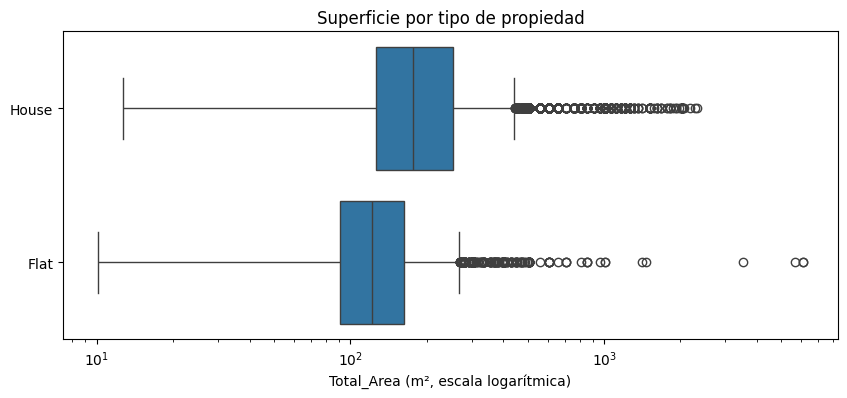

In [726]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="Total_Area", y="property_type", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Total_Area (m², escala logarítmica)")
ax.set_ylabel("")
ax.set_title("Superficie por tipo de propiedad")
plt.show()

**Decisión 1: superficie mínima.** Un anuncio con menos de 10 m² no es una vivienda real. Miramos cuáles son.

In [727]:
menores = df[df["Total_Area"] < 10]
print(f"Anuncios con Total_Area < 10 m²: {len(menores)}")
menores[["property_type", "price", "Total_Area", "bedrooms"]]

Anuncios con Total_Area < 10 m²: 0


,property_type,price,Total_Area,bedrooms


Son anuncios de casas con 2 a 5 habitaciones y **0 m²**: el cero es un dato que falta, no una superficie real. Son pocos (7 filas, el 0,01 %) y no hay forma fiable de recuperar el valor, así que **se eliminan**.

**Decisión 2: superficie máxima en el resto de tipos.** Una planta de una casa (`Upper Portion`, `Lower Portion`), un `Penthouse` o una `Room` no puede ser mayor que una casa entera. Aplicamos el mismo límite que a las casas (2.500 m²).

`Farm House` **no se toca**: una granja puede ser legítimamente muy grande (la mediana es de unos 4.000 m²), así que sus valores altos son atípicos reales, no errores.

In [728]:
TIPOS_PARCIALES = ["Upper Portion", "Lower Portion", "Penthouse", "Room"]
mask = df["property_type"].isin(TIPOS_PARCIALES) & (df["Total_Area"] > 2500)
print(f"Filas que superan 2.500 m² (tipos parciales): {mask.sum()}")
print(df[mask]["property_type"].value_counts())

df = df[~mask].reset_index(drop=True)

Filas que superan 2.500 m² (tipos parciales): 0
Series([], Name: count, dtype: int64)


### Precio (`price`)

**Hallazgo.** El precio tiene una asimetría muy fuerte y, en el extremo bajo, hay anuncios con precios de unos pocos euros, que no corresponden a una venta real (probablemente alquileres o errores de escritura).

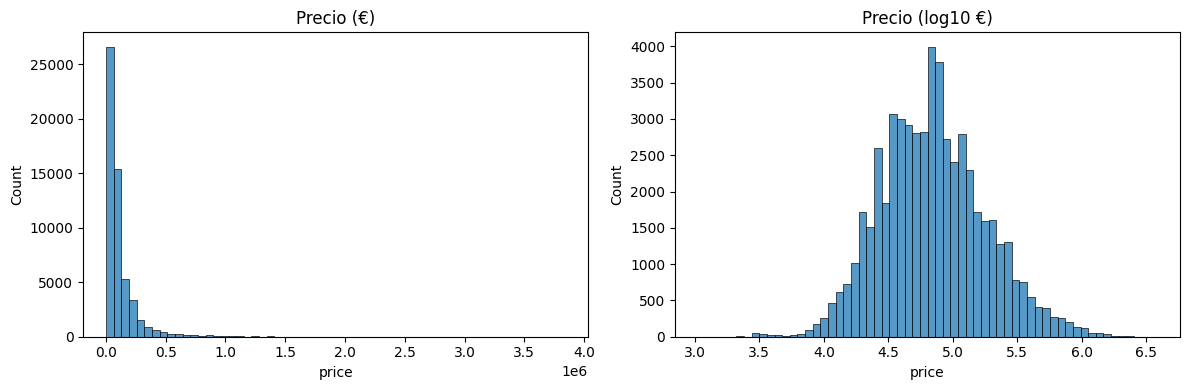

Precios por debajo de 1.000 €: 0


Series([], dtype: int64)

In [729]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title("Precio (€)")
sns.histplot(np.log10(df["price"].clip(lower=1)), bins=60, ax=axes[1])
axes[1].set_title("Precio (log10 €)")
plt.tight_layout()
plt.show()

print("Precios por debajo de 1.000 €:", (df["price"] < 1000).sum())
df[df["price"] < 1000].groupby("property_type").size()

**Decisión 3: precio mínimo.** Por debajo de 1.000 € (unas 180.000 rupias) no hay ninguna casa, piso ni piso parcial a la venta con sentido. Son pocos anuncios (0,1 %) y no se pueden corregir, así que **se eliminan**.

**Decisión 4: precios altos, se conservan.** Calculamos cuántos anuncios quedan fuera del criterio IQR y qué efecto tiene un logaritmo.

In [730]:
q1, q3 = df["price"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
n_altos = (df["price"] > limite).sum()
print(f"Límite superior IQR: {limite:,.0f} € -> {n_altos} anuncios ({n_altos / len(df):.1%})")
print(f"Asimetría de price:      {df['price'].skew():.2f}")
print(f"Asimetría de log(price): {np.log(df['price']).skew():.2f}")

Límite superior IQR: 263,070 € -> 4702 anuncios (8.5%)
Asimetría de price:      5.33
Asimetría de log(price): 0.25


Hay un grupo grande de anuncios por encima del límite IQR, pero **no se eliminan**: son propiedades caras de verdad (casas grandes en zonas como DHA o Bani Gala), no errores. Quitarlos haría que el modelo no supiera estimar el segmento alto.

**Acción:** mantenerlos y tratar la asimetría con `log(price)` como variable objetivo (se decide en el EDA y en la fase de modelado).

In [731]:
print(f"Filas de partida de esta vuelta: {n_inicial_3v}")
print(f"Filas finales:                     {len(df)}")
print(f"Filas eliminadas en total:         {n_inicial_3v - len(df)}")
df.shape

Filas de partida de esta vuelta: 55404
Filas finales:                     55404
Filas eliminadas en total:         0


(55404, 10)

### Resumen de la tercera vuelta

| Hallazgo | Acción | Justificación | Filas eliminadas |
|---|---|---|---|
| `Total_Area` < 10 m² (en realidad 0 m²) | Eliminar | El cero es un dato ausente, no recuperable | 7 |
| `Upper Portion`, `Lower Portion`, `Penthouse` y `Room` con más de 2.500 m² | Eliminar | Una parte de una casa no puede superar a una casa entera (mismo límite que `House`) | 157 |
| `Farm House` con superficies muy grandes | Conservar | Son valores atípicos reales | 0 |
| `price` < 1.000 € | Eliminar | No corresponde a una venta real y no se puede corregir | 57 |
| `price` por encima del límite IQR | Conservar | Propiedades caras reales; se trata con `log(price)` | 0 |


In [732]:
df

,location_id,property_type,price,location,city,baths,bedrooms,date_added,dist_centro_km,Total_Area
0,4312,House,144758.09,Wapda Town,Lahore,5,5,2018-08-05,17.21,252.93
1,373,House,130839.04,Valencia Housing Society,Lahore,6,5,2018-08-07,20.81,265.57
2,3725,House,180947.61,Dharampura,Lahore,6,6,2018-08-07,4.42,303.51
3,4354,House,40643.62,Rana Town,Lahore,5,4,2018-08-07,12.74,126.46
4,8152,House,52892.38,Zaitoon - New Lahore City,Lahore,5,3,2018-08-07,31.58,126.46
...,...,...,...,...,...,...,...,...,...,...
55399,8152,House,41757.14,Zaitoon - New Lahore City,Lahore,3,3,2019-08-06,31.58,126.46
55400,7,House,835142.81,Gulberg,Lahore,4,4,2019-08-06,6.85,1011.71
55401,1615,House,270029.51,DHA Defence,Lahore,6,5,2019-08-06,17.77,505.86
55402,9996,House,55676.19,Lalazaar Garden,Lahore,4,4,2019-08-06,11.28,126.46
